In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset.csv")

df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [2]:
genres = ["pop", "rock", "hip-hop", "jazz", "classical"]

df = df[df["track_genre"].isin(genres)]

print(df.shape)
print(df["track_genre"].value_counts())

(5000, 21)
track_genre
classical    1000
hip-hop      1000
jazz         1000
pop          1000
rock         1000
Name: count, dtype: int64


In [3]:
print(df.isnull().sum())

print("Duplicate tracks:", df["track_id"].duplicated().sum())

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
Duplicate tracks: 206


In [4]:
df = df.drop_duplicates(subset="track_id").reset_index(drop=True)

print("Total songs:", len(df))
print("Duplicate tracks:", df["track_id"].duplicated().sum())
print(df["track_genre"].value_counts())

Total songs: 4794
Duplicate tracks: 0
track_genre
hip-hop      991
rock         991
jazz         989
classical    933
pop          890
Name: count, dtype: int64


In [5]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

X = df[features]
y = df["track_genre"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4794, 9)
y shape: (4794,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training songs:", len(X_train))
print("Testing songs:", len(X_test))

Training songs: 3835
Testing songs: 959


In [8]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=5, random_state=42)

model.fit(X_train, y_train)

print("Decision Tree model trained!")

Decision Tree model trained!


In [10]:
from sklearn.metrics import accuracy_score

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

Training Accuracy: 66.49 %
Testing Accuracy: 64.55 %


In [11]:
results = df.loc[X_test.index].copy()

results["predicted_genre"] = test_predictions

wrong_predictions = results[
    results["track_genre"] != results["predicted_genre"]
]

wrong_predictions[[
    "track_name",
    "artists",
    "track_genre",
    "predicted_genre"
]].head(5)

,track_name,artists,track_genre,predicted_genre
3398,Waalian,Harnoor,pop,jazz
3416,Quemando Calorías,Feid;Sky Rompiendo,pop,rock
4,Zara Zara - LoFi Chill,Bombay Jayashri;Swattrex,classical,jazz
397,Aamhi Vithlache Warkari,Bhimsen Joshi;Pt. Jitender Abhisheki;Ajit Kadkade,classical,jazz
4495,Spirits,The Strumbellas,rock,pop


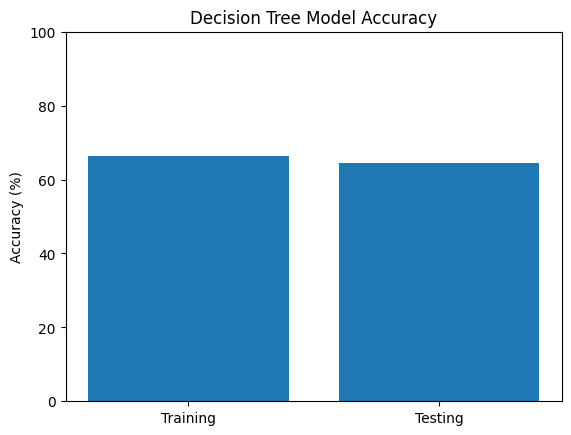

In [12]:
accuracy_values = [train_accuracy * 100, test_accuracy * 100]

plt.bar(["Training", "Testing"], accuracy_values)

plt.title("Decision Tree Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

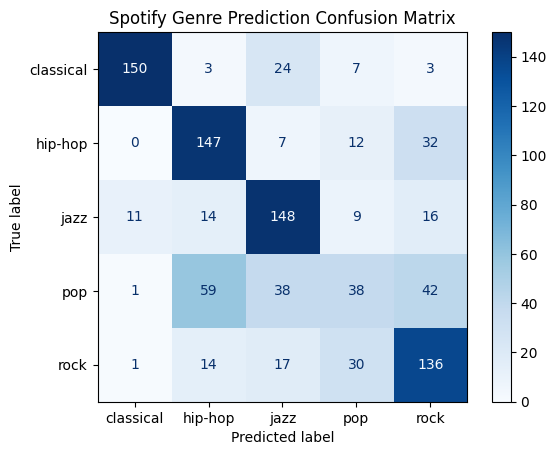

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    cmap="Blues"
)

plt.title("Spotify Genre Prediction Confusion Matrix")
plt.show()

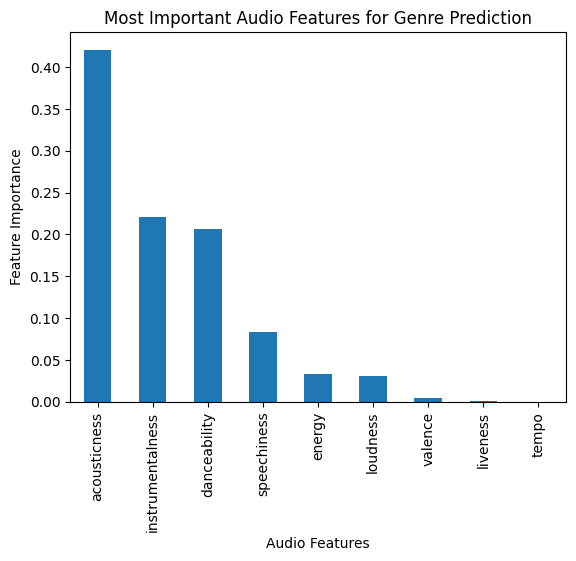

In [14]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

feature_importance.plot(kind="bar")

plt.title("Most Important Audio Features for Genre Prediction")
plt.xlabel("Audio Features")
plt.ylabel("Feature Importance")
plt.show()

In [15]:
depth_results = []

for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    train_acc = tree.score(X_train, y_train)
    test_acc = tree.score(X_test, y_test)

    depth_results.append({
        "depth": depth,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

depth_df = pd.DataFrame(depth_results)

depth_df

,depth,train_accuracy,test_accuracy
0,1,0.380183,0.384776
1,2,0.583833,0.610010
2,3,0.599739,0.600626
3,4,0.628162,0.615224
4,5,0.664928,0.645464
5,6,0.701956,0.655892
6,7,0.741069,0.666319
7,8,0.783833,0.690302
8,9,0.820600,0.714286
9,10,0.860495,0.712200


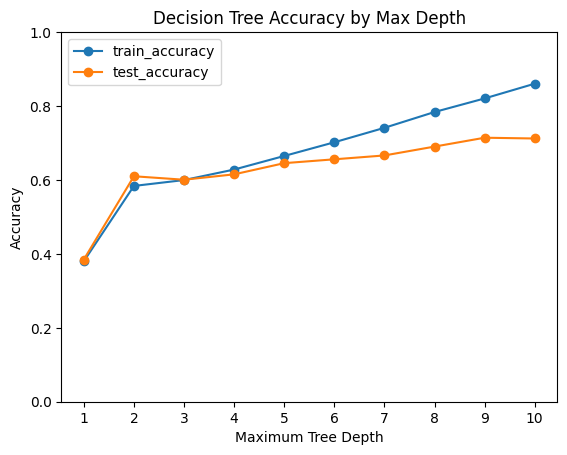

In [16]:
depth_df.plot(
    x="depth",
    y=["train_accuracy", "test_accuracy"],
    marker="o"
)

plt.title("Decision Tree Accuracy by Max Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.xticks(range(1, 11))
plt.ylim(0, 1)
plt.show()